# KM6312 Group Project — Exploratory Data Analysis (`bank-additional-full.csv`)
**Objective:** Perform a standalone Exploratory Data Analysis (EDA) on the UCI Bank Marketing dataset (`bank-additional-full.csv`, 41,188 raw rows) strictly following the group's data processing pipeline, without training any models, splitting, scaling, or one-hot encoding.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

COLOR_NO = '#4C72B0'
COLOR_YES = '#DD8452'
COLOR_MAIN = '#2B5C8F'
COLOR_WARN = '#C44E52'


## 1. Data Processing & Data Quality Audit (Duplicates, Missing Values, and `"unknown"` Counts)
Following `DemoBankmodels.ipynb`:
1. Read `bank-additional-full.csv` with `sep=";"`.
2. Drop exact duplicate rows (`12` duplicates dropped: `41,188 -> 41,176` rows).
3. Map target `y`: `'no' -> 0`, `'yes' -> 1`.
4. Split `pdays` (`999` = never contacted before) into `previously_contacted` (`0/1`) and `pdays_clean` (`999 -> 0`), then drop `pdays`.
5. **Final Shape:** `(41176, 22)`.


In [2]:
# 1. Load raw data and audit duplicates / missing values
df_raw = pd.read_csv('bank-additional-full.csv', sep=';')
print(f"Raw dataset shape: {df_raw.shape}")
print(f"Standard NA/null values across all columns: {df_raw.isna().sum().sum()}")
print(f"Exact duplicate rows in raw data: {df_raw.duplicated().sum()}")

# 2. Apply exact Data Processing steps from DemoBankmodels.ipynb
df = df_raw.drop_duplicates().copy()
df['y'] = df['y'].map({'no': 0, 'yes': 1})
df['previously_contacted'] = (df['pdays'] != 999).astype(int)
df['pdays_clean'] = df['pdays'].replace(999, 0)
df = df.drop(columns=['pdays'])

print(f"Final processed dataset shape: {df.shape}")
BASE_RATE = df['y'].mean() * 100
print(f"Overall Subscription Rate (y=1): {BASE_RATE:.2f}% ({df['y'].sum():,} / {len(df):,})")


Raw dataset shape: (41188, 21)
Standard NA/null values across all columns: 0
Exact duplicate rows in raw data: 12
Final processed dataset shape: (41176, 22)
Overall Subscription Rate (y=1): 11.27% (4,639 / 41,176)


In [3]:
# 3. Audit 'unknown' string values across categorical variables
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
unk_summary = []
for col in cat_cols:
    unk_n = int((df[col] == 'unknown').sum())
    unk_pct = unk_n / len(df) * 100
    raw_unk_n = int((df_raw[col] == 'unknown').sum())
    unk_rate = df.loc[df[col] == 'unknown', 'y'].mean() * 100 if unk_n > 0 else np.nan
    unk_summary.append({
        'column': col,
        'unknown_count_dedup': unk_n,
        'unknown_pct_dedup': round(unk_pct, 2),
        'unknown_count_raw': raw_unk_n,
        'unknown_sub_rate_%': round(unk_rate, 2) if not np.isnan(unk_rate) else None,
        'small_n_flag (<1000)': (0 < unk_n < 1000)
    })
unk_audit_df = pd.DataFrame(unk_summary).sort_values(by='unknown_count_dedup', ascending=False)
print(unk_audit_df.to_string(index=False))


     column  unknown_count_dedup  unknown_pct_dedup  unknown_count_raw  unknown_sub_rate_%  small_n_flag (<1000)
    default                 8596              20.88               8597                5.15                 False
  education                 1730               4.20               1731               14.51                 False
    housing                  990               2.40                990               10.81                  True
       loan                  990               2.40                990               10.81                  True
        job                  330               0.80                330               11.21                  True
    marital                   80               0.19                 80               15.00                  True
    contact                    0               0.00                  0                 NaN                 False
      month                    0               0.00                  0                 NaN      

/var/folders/zd/vxjrh_910633twnxq59hxlcm0000gn/T/ipykernel_21059/1856752334.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns.tolist()


## 2. Target Distribution (`fig1_target_distribution.png`)


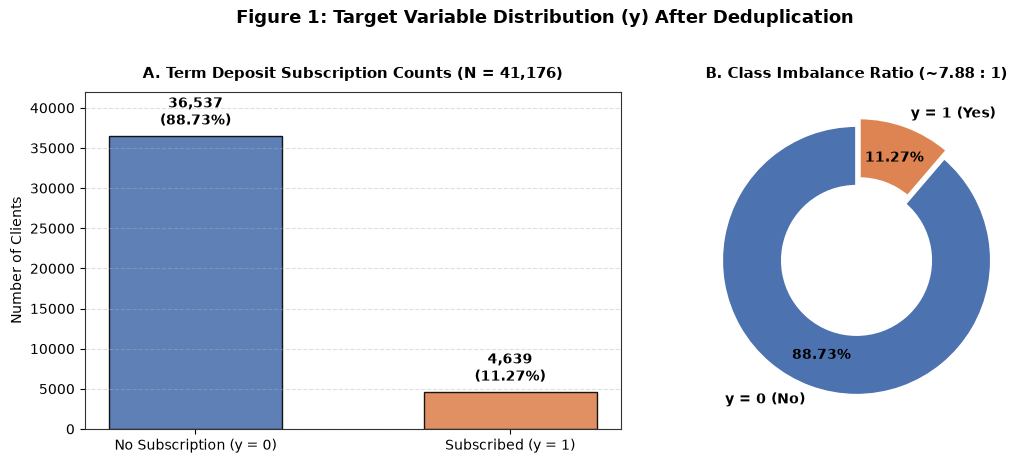

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1.2, 1]})
y_counts = df['y'].value_counts().sort_index()
y_pcts = y_counts / len(df) * 100
labels = ['No Subscription (y = 0)', 'Subscribed (y = 1)']
colors = [COLOR_NO, COLOR_YES]

bars = axes[0].bar(labels, y_counts.values, color=colors, width=0.55, edgecolor='black', alpha=0.9)
axes[0].set_title('A. Term Deposit Subscription Counts (N = 41,176)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_ylabel('Number of Clients', fontsize=10)
axes[0].set_ylim(0, 42000)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
for bar, cnt, pct in zip(bars, y_counts.values, y_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, cnt + 800,
                 f'{cnt:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].pie(
    y_counts.values, labels=['y = 0 (No)', 'y = 1 (Yes)'],
    autopct='%1.2f%%', startangle=90, colors=colors,
    pctdistance=0.75, explode=(0, 0.06),
    textprops={'fontsize': 10, 'fontweight': 'bold'},
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('B. Class Imbalance Ratio (~7.88 : 1)', fontsize=11, fontweight='bold', pad=10)
plt.suptitle('Figure 1: Target Variable Distribution (y) After Deduplication', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig1_target_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


## 3. Distributions of Numeric Variables (`fig2_numeric_distributions.png`)


                        count     mean     std      min      25%      50%      75%      max     IQR
age                   41176.0    40.02   10.42    17.00    32.00    38.00    47.00    98.00   15.00
duration              41176.0   258.32  259.31     0.00   102.00   180.00   319.00  4918.00  217.00
campaign              41176.0     2.57    2.77     1.00     1.00     2.00     3.00    56.00    2.00
previous              41176.0     0.17    0.49     0.00     0.00     0.00     0.00     7.00    0.00
previously_contacted  41176.0     0.04    0.19     0.00     0.00     0.00     0.00     1.00    0.00
pdays_clean           41176.0     0.22    1.35     0.00     0.00     0.00     0.00    27.00    0.00
emp.var.rate          41176.0     0.08    1.57    -3.40    -1.80     1.10     1.40     1.40    3.20
cons.price.idx        41176.0    93.58    0.58    92.20    93.08    93.75    93.99    94.77    0.92
cons.conf.idx         41176.0   -40.50    4.63   -50.80   -42.70   -41.80   -36.40   -26.90    6.30


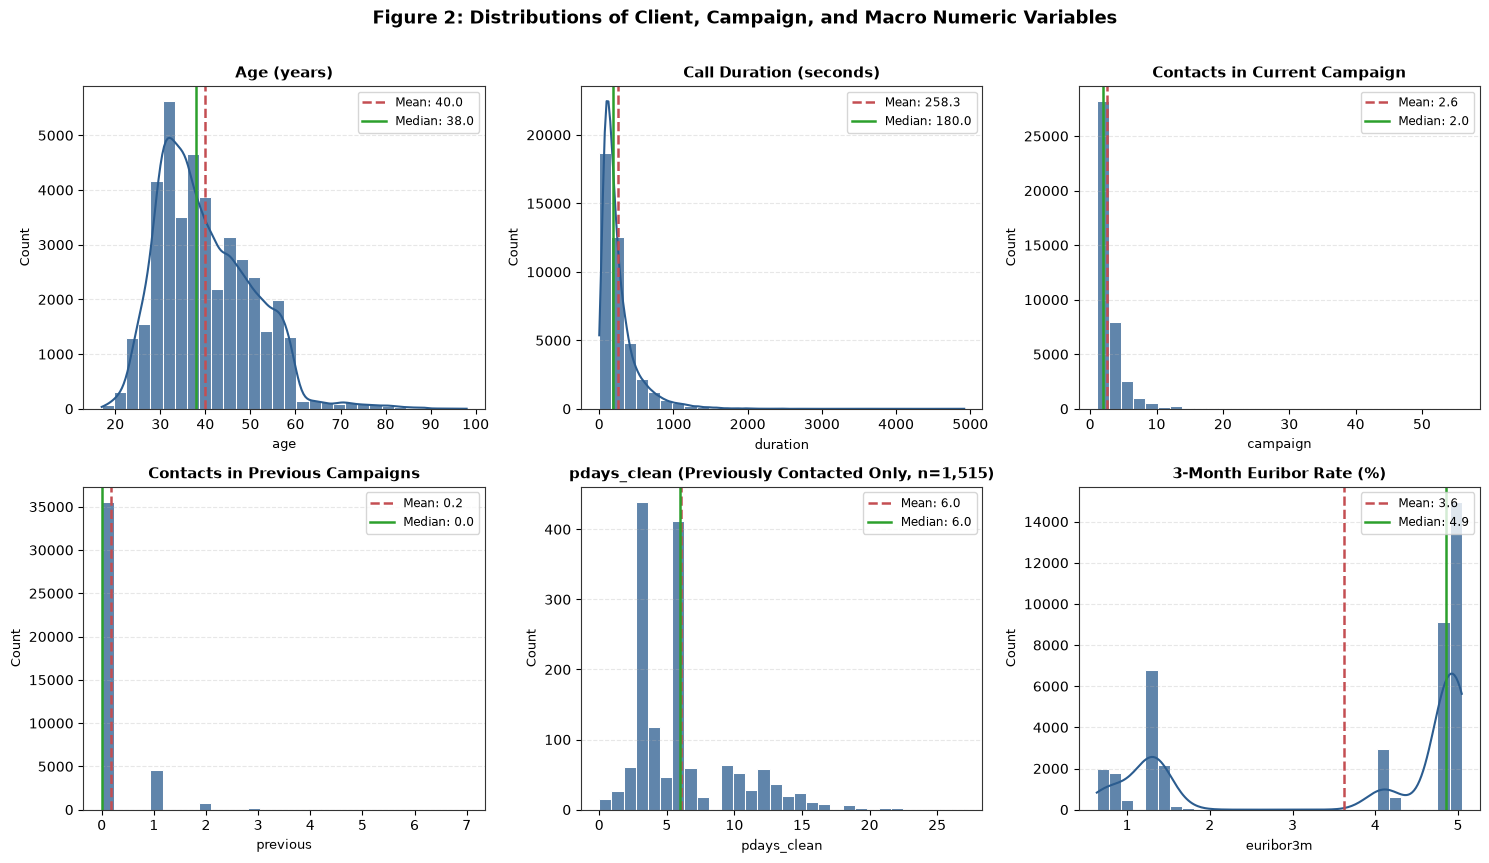

In [5]:
num_cols = ['age', 'duration', 'campaign', 'previous', 'previously_contacted', 'pdays_clean',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
print(num_summary.round(2).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
plot_specs = [
    ('age', 'Age (years)', False),
    ('duration', 'Call Duration (seconds)', False),
    ('campaign', 'Contacts in Current Campaign', False),
    ('previous', 'Contacts in Previous Campaigns', False),
    ('pdays_clean', 'pdays_clean (Previously Contacted Only, n=1,515)', True),
    ('euribor3m', '3-Month Euribor Rate (%)', False)
]

for idx, (col, title, filter_pc) in enumerate(plot_specs):
    ax = axes[idx]
    data_ser = df.loc[df['previously_contacted'] == 1, col] if filter_pc else df[col]
    sns.histplot(data_ser, bins=30, kde=(col in ['age', 'duration', 'euribor3m']),
                 color=COLOR_MAIN, edgecolor='white', alpha=0.75, ax=ax)
    mean_v, med_v = data_ser.mean(), data_ser.median()
    ax.axvline(mean_v, color=COLOR_WARN, linestyle='--', linewidth=1.8, label=f'Mean: {mean_v:.1f}')
    ax.axvline(med_v, color='#2CA02C', linestyle='-', linewidth=1.8, label=f'Median: {med_v:.1f}')
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_xlabel(col, fontsize=9.5)
    ax.set_ylabel('Count', fontsize=9.5)
    ax.legend(fontsize=8.5, loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle('Figure 2: Distributions of Client, Campaign, and Macro Numeric Variables', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig2_numeric_distributions.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. How Numeric Variables Differ by Target `y` (`fig3_numeric_by_target.png`)


            variable  y0_mean  y0_median  y0_IQR  y1_mean  y1_median  y1_IQR
                 age    39.91      38.00   15.00    40.91      37.00   19.00
            duration   220.87     164.00  184.00   553.26     449.00  488.00
            campaign     2.63       2.00    2.00     2.05       2.00    1.00
            previous     0.13       0.00    0.00     0.49       0.00    1.00
previously_contacted     0.01       0.00    0.00     0.21       0.00    0.00
         pdays_clean     0.09       0.00    0.00     1.23       0.00    0.00
        emp.var.rate     0.25       1.10    3.20    -1.23      -1.80    1.70
      cons.price.idx    93.60      93.92    0.92    93.35      93.20    1.03
       cons.conf.idx   -40.59     -41.80    6.30   -39.79     -40.40   10.10
           euribor3m     3.81       4.86    3.56     2.12       1.27    3.56
         nr.employed  5176.17    5195.80  129.00  5095.12    5099.10  173.50


/var/folders/zd/vxjrh_910633twnxq59hxlcm0000gn/T/ipykernel_21059/611014808.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='y_label', y=col, order=['No (y=0)', 'Yes (y=1)'],
/var/folders/zd/vxjrh_910633twnxq59hxlcm0000gn/T/ipykernel_21059/611014808.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='y_label', y=col, order=['No (y=0)', 'Yes (y=1)'],
/var/folders/zd/vxjrh_910633twnxq59hxlcm0000gn/T/ipykernel_21059/611014808.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='y_label', y=col, orde

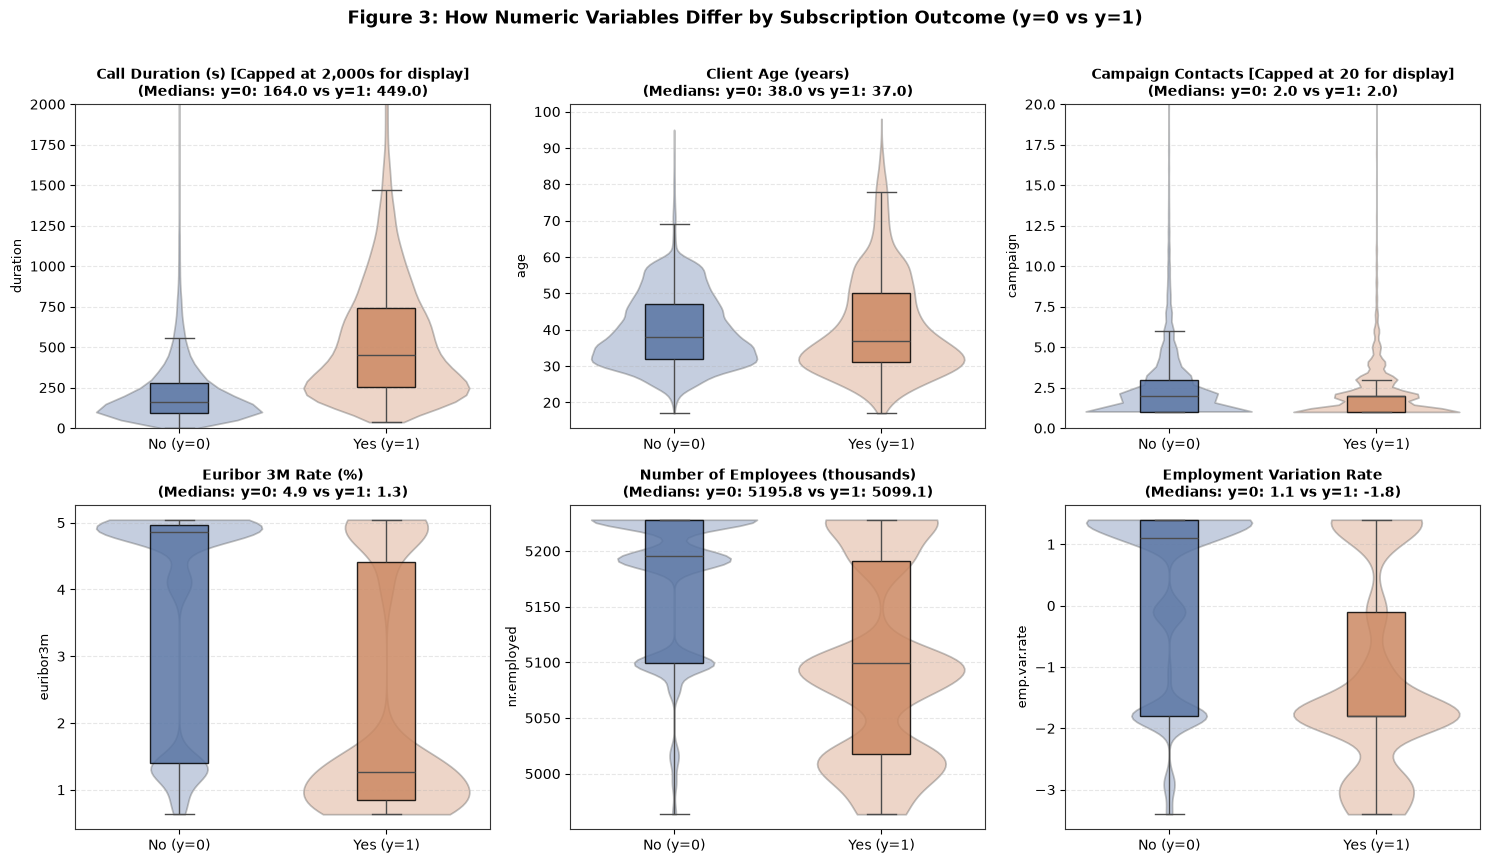

In [6]:
by_y_table = []
for col in num_cols:
    g0, g1 = df.loc[df['y']==0, col], df.loc[df['y']==1, col]
    by_y_table.append({
        'variable': col,
        'y0_mean': round(g0.mean(), 2), 'y0_median': round(g0.median(), 2), 'y0_IQR': round(g0.quantile(0.75)-g0.quantile(0.25), 2),
        'y1_mean': round(g1.mean(), 2), 'y1_median': round(g1.median(), 2), 'y1_IQR': round(g1.quantile(0.75)-g1.quantile(0.25), 2)
    })
print(pd.DataFrame(by_y_table).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
df['y_label'] = df['y'].map({0: 'No (y=0)', 1: 'Yes (y=1)'})
by_y_specs = [
    ('duration', 'Call Duration (s) [Capped at 2,000s for display]', (0, 2000)),
    ('age', 'Client Age (years)', None),
    ('campaign', 'Campaign Contacts [Capped at 20 for display]', (0, 20)),
    ('euribor3m', 'Euribor 3M Rate (%)', None),
    ('nr.employed', 'Number of Employees (thousands)', None),
    ('emp.var.rate', 'Employment Variation Rate', None)
]

for idx, (col, title, ylim) in enumerate(by_y_specs):
    ax = axes[idx]
    sns.violinplot(data=df, x='y_label', y=col, order=['No (y=0)', 'Yes (y=1)'],
                   palette=[COLOR_NO, COLOR_YES], inner=None, alpha=0.35, ax=ax, cut=0)
    sns.boxplot(data=df, x='y_label', y=col, order=['No (y=0)', 'Yes (y=1)'],
                width=0.28, palette=[COLOR_NO, COLOR_YES], showfliers=False,
                boxprops=dict(alpha=0.85, edgecolor='black'), ax=ax)
    if ylim:
        ax.set_ylim(ylim)
    med0 = df.loc[df['y']==0, col].median()
    med1 = df.loc[df['y']==1, col].median()
    ax.set_title(f"{title}\n(Medians: y=0: {med0:.1f} vs y=1: {med1:.1f})", fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

df.drop(columns=['y_label'], inplace=True)
plt.suptitle('Figure 3: How Numeric Variables Differ by Subscription Outcome (y=0 vs y=1)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig3_numeric_by_target.png', dpi=200, bbox_inches='tight')
plt.show()


## 5. Correlations Between Numeric Variables (`fig4_correlation_heatmap.png`)


y                       1.0000
duration                0.4053
previously_contacted    0.3249
pdays_clean             0.2671
previous                0.2302
cons.conf.idx           0.0548
age                     0.0304
campaign               -0.0664
cons.price.idx         -0.1361
emp.var.rate           -0.2983
euribor3m              -0.3077
nr.employed            -0.3547
Name: y, dtype: float64


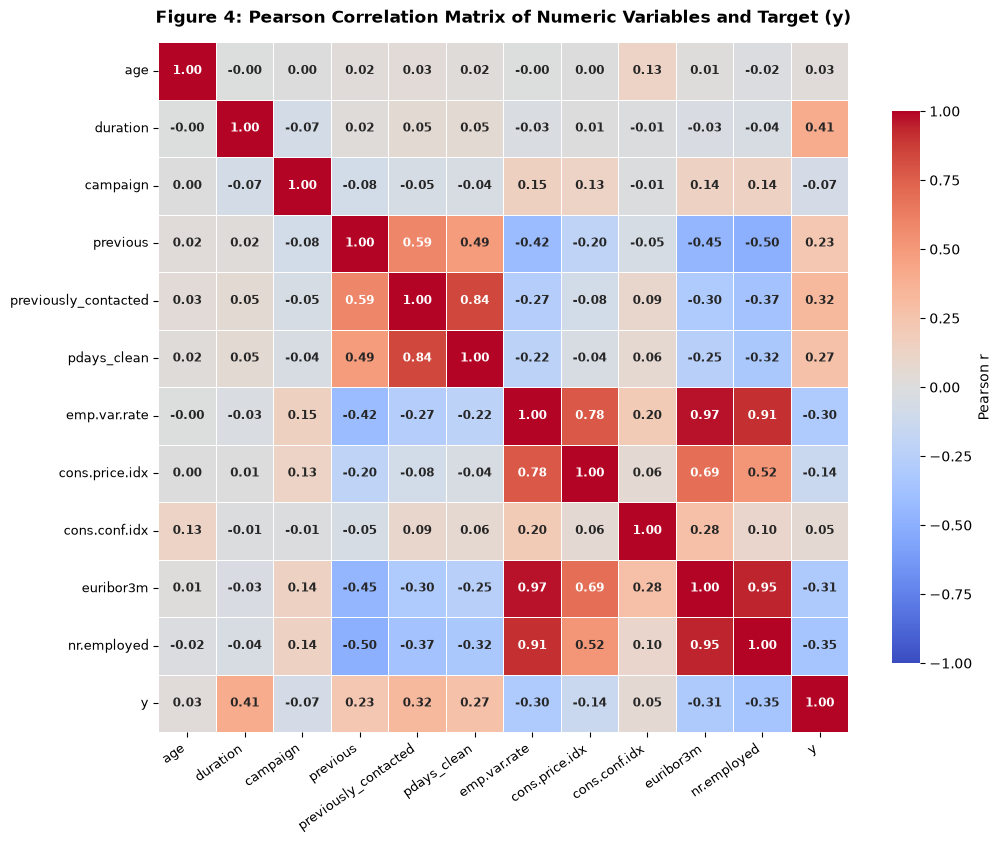

In [7]:
corr_cols = num_cols + ['y']
corr_mat = df[corr_cols].corr()
print(corr_mat['y'].sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.6, cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}, ax=ax,
            annot_kws={'size': 8.5, 'fontweight': 'bold'})
ax.set_title('Figure 4: Pearson Correlation Matrix of Numeric Variables and Target (y)', fontsize=12.5, fontweight='bold', pad=14)
plt.xticks(rotation=35, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()
plt.savefig('fig4_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()


## 6. Subscription Rates by Categorical Variables (`fig5`, `fig6`, `fig7`)


          job     n  yes      rate
      student   875  275 31.428571
      retired  1718  434 25.261932
   unemployed  1014  144 14.201183
       admin. 10419 1351 12.966695
   management  2924  328 11.217510
      unknown   330   37 11.212121
   technician  6739  730 10.832468
self-employed  1421  149 10.485574
    housemaid  1060  106 10.000000
 entrepreneur  1456  124  8.516484
     services  3967  323  8.142173
  blue-collar  9253  638  6.895061


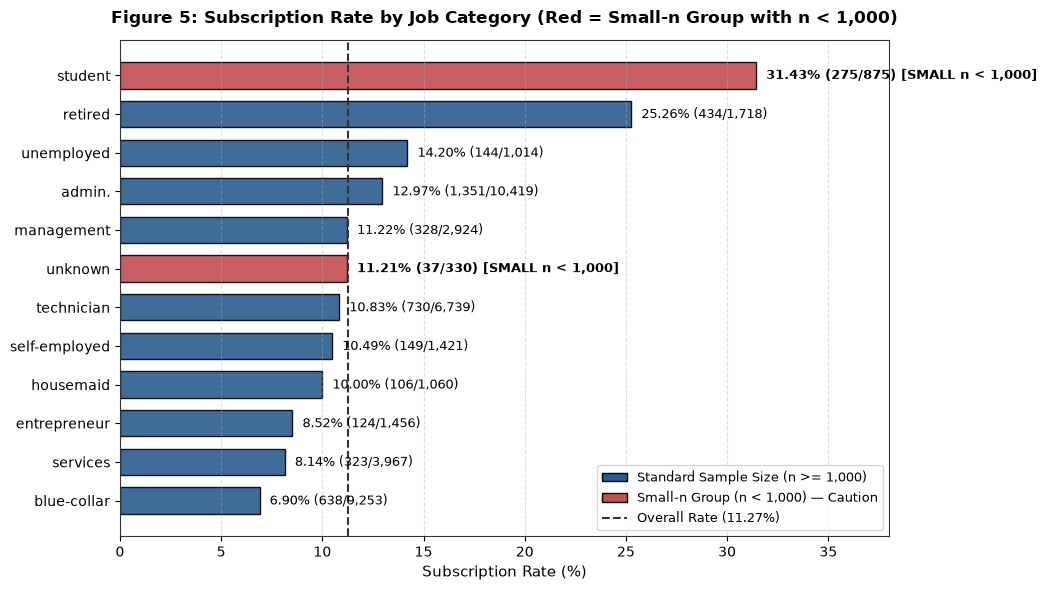

In [8]:
# Figure 5: Job Category Subscription Rates
job_stats = df.groupby('job')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reset_index()
job_stats = job_stats.sort_values(by='rate', ascending=True)
print(job_stats.sort_values(by='rate', ascending=False).to_string(index=False))

fig, ax = plt.subplots(figsize=(10.5, 6))
bar_colors = [COLOR_WARN if n < 1000 else COLOR_MAIN for n in job_stats['n']]
bars = ax.barh(job_stats['job'], job_stats['rate'], color=bar_colors, edgecolor='black', height=0.68, alpha=0.9)
ax.axvline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.5, label=f'Overall Base Rate ({BASE_RATE:.2f}%)')
ax.set_xlim(0, 38)
ax.set_xlabel('Subscription Rate (%)', fontsize=10.5)
ax.set_title('Figure 5: Subscription Rate by Job Category (Red = Small-n Group with n < 1,000)', fontsize=12, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for bar, (_, row) in zip(bars, job_stats.iterrows()):
    flag_txt = ' [SMALL n < 1,000]' if row['n'] < 1000 else ''
    ax.text(row['rate'] + 0.5, bar.get_y() + bar.get_height()/2,
            f"{row['rate']:.2f}% ({int(row['yes']):,}/{int(row['n']):,}){flag_txt}",
            va='center', ha='left', fontsize=9, fontweight=('bold' if row['n'] < 1000 else 'normal'))

legend_elements = [
    Patch(facecolor=COLOR_MAIN, edgecolor='black', label='Standard Sample Size (n >= 1,000)'),
    Patch(facecolor=COLOR_WARN, edgecolor='black', label='Small-n Group (n < 1,000) — Caution'),
    Line2D([0], [0], color='#333333', lw=1.5, ls='--', label=f'Overall Rate ({BASE_RATE:.2f}%)')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('fig5_job_subscription_rates.png', dpi=200, bbox_inches='tight')
plt.show()


month     n  yes      rate
  mar   546  276 50.549451
  apr  2631  539 20.486507
  may 13767  886  6.435680
  jun  5318  559 10.511470
  jul  7169  648  9.038918
  aug  6176  655 10.605570
  sep   570  256 44.912281
  oct   717  315 43.933054
  nov  4100  416 10.146341
  dec   182   89 48.901099


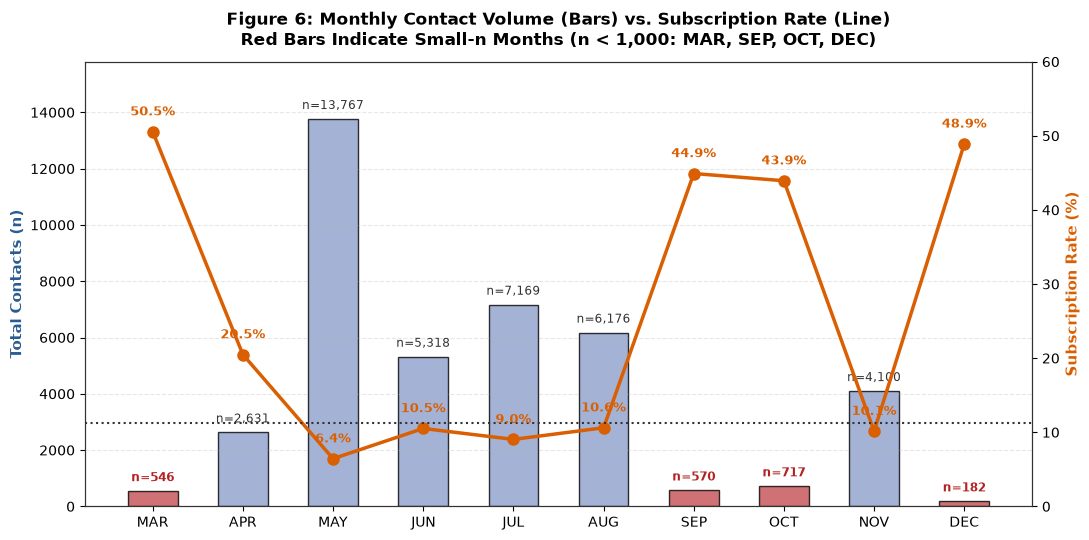

In [9]:
# Figure 6: Monthly Contact Volume & Subscription Rate
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
m_stats = df.groupby('month')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reindex(month_order).reset_index()
print(m_stats.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax2 = ax1.twinx()

bar_cols_m = [COLOR_WARN if n < 1000 else '#8DA0CB' for n in m_stats['n']]
ax1.bar(m_stats['month'].str.upper(), m_stats['n'], color=bar_cols_m, edgecolor='black', width=0.55, alpha=0.8)
ax2.plot(m_stats['month'].str.upper(), m_stats['rate'], color='#D95F02', marker='o', linewidth=2.5, markersize=8)
ax2.axhline(BASE_RATE, color='#333333', linestyle=':', linewidth=1.5)

ax1.set_ylabel('Total Contacts (n)', fontsize=10.5, color='#2B5C8F', fontweight='bold')
ax2.set_ylabel('Subscription Rate (%)', fontsize=10.5, color='#D95F02', fontweight='bold')
ax1.set_ylim(0, 15800)
ax2.set_ylim(0, 60)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

for idx, row in m_stats.iterrows():
    ax1.text(idx, row['n'] + 250, f"n={int(row['n']):,}", ha='center', va='bottom', fontsize=8.5,
             color=('#B22222' if row['n'] < 1000 else '#333333'), fontweight=('bold' if row['n'] < 1000 else 'normal'))
    ax2.text(idx, row['rate'] + 1.8, f"{row['rate']:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#D95F02')

ax1.set_title('Figure 6: Monthly Contact Volume (Bars) vs. Subscription Rate (Line)\nRed Bars Indicate Small-n Months (n < 1,000: MAR, SEP, OCT, DEC)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('fig6_month_volume_and_rate.png', dpi=200, bbox_inches='tight')
plt.show()



--- poutcome ---
   poutcome     n  yes      rate
    success  1373  894 65.112891
    failure  4252  605 14.228598
nonexistent 35551 3140  8.832382

--- contact ---
  contact     n  yes      rate
 cellular 26135 3852 14.738856
telephone 15041  787  5.232365

--- previously_contacted ---
 previously_contacted     n  yes      rate
                    1  1515  967 63.828383
                    0 39661 3672  9.258465


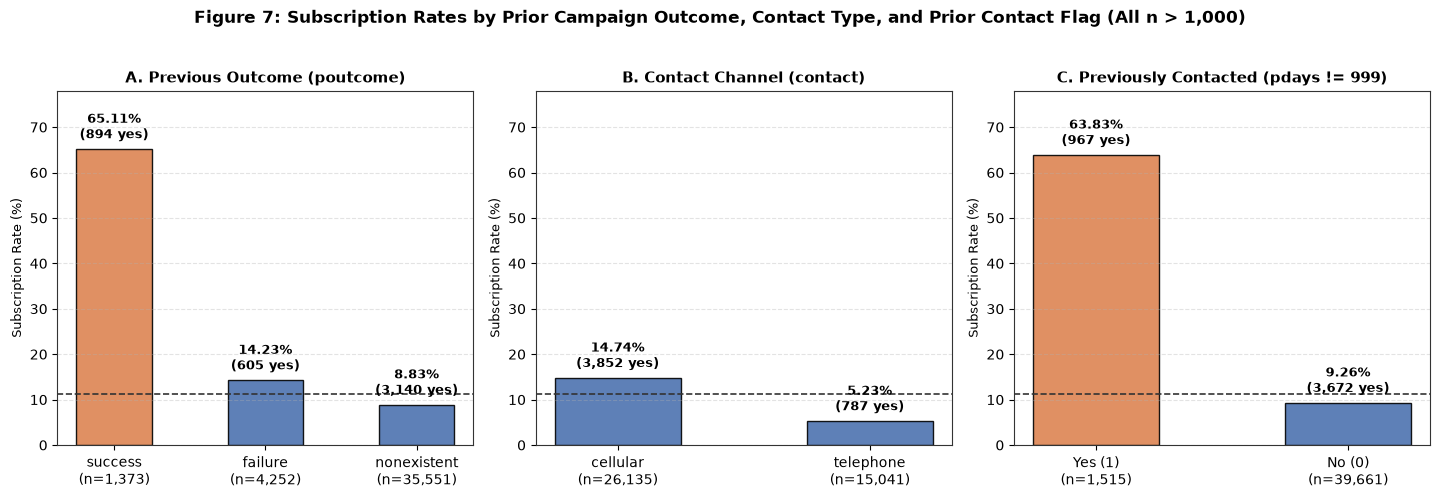

In [10]:
# Figure 7: poutcome, contact, and previously_contacted
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8))
cat_panels = [
    ('poutcome', 'A. Previous Outcome (poutcome)', ['success', 'failure', 'nonexistent']),
    ('contact', 'B. Contact Channel (contact)', ['cellular', 'telephone']),
    ('previously_contacted', 'C. Previously Contacted (pdays != 999)', [1, 0])
]

for ax, (col, title, order) in zip(axes, cat_panels):
    st = df.groupby(col)['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reindex(order).reset_index()
    print(f"\n--- {col} ---")
    print(st.to_string(index=False))
    x_labels = [f"{str(val)}\n(n={int(n):,})" for val, n in zip(st[col], st['n'])]
    if col == 'previously_contacted':
        x_labels = [f"{'Yes (1)' if val==1 else 'No (0)'}\n(n={int(n):,})" for val, n in zip(st[col], st['n'])]
    bars = ax.bar(x_labels, st['rate'], color=[COLOR_YES if r > 20 else COLOR_NO for r in st['rate']],
                  edgecolor='black', width=0.5, alpha=0.9)
    ax.axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
    ax.set_ylim(0, 78)
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Subscription Rate (%)', fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    for bar, (_, row) in zip(bars, st.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, row['rate'] + 1.5,
                f"{row['rate']:.2f}%\n({int(row['yes']):,} yes)", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Figure 7: Subscription Rates by Prior Campaign Outcome, Contact Type, and Prior Contact Flag (All n > 1,000)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('fig7_poutcome_contact_rates.png', dpi=200, bbox_inches='tight')
plt.show()


## 7. Macro / Social-Economic Indicators (`fig8_macro_regimes_analysis.png`)


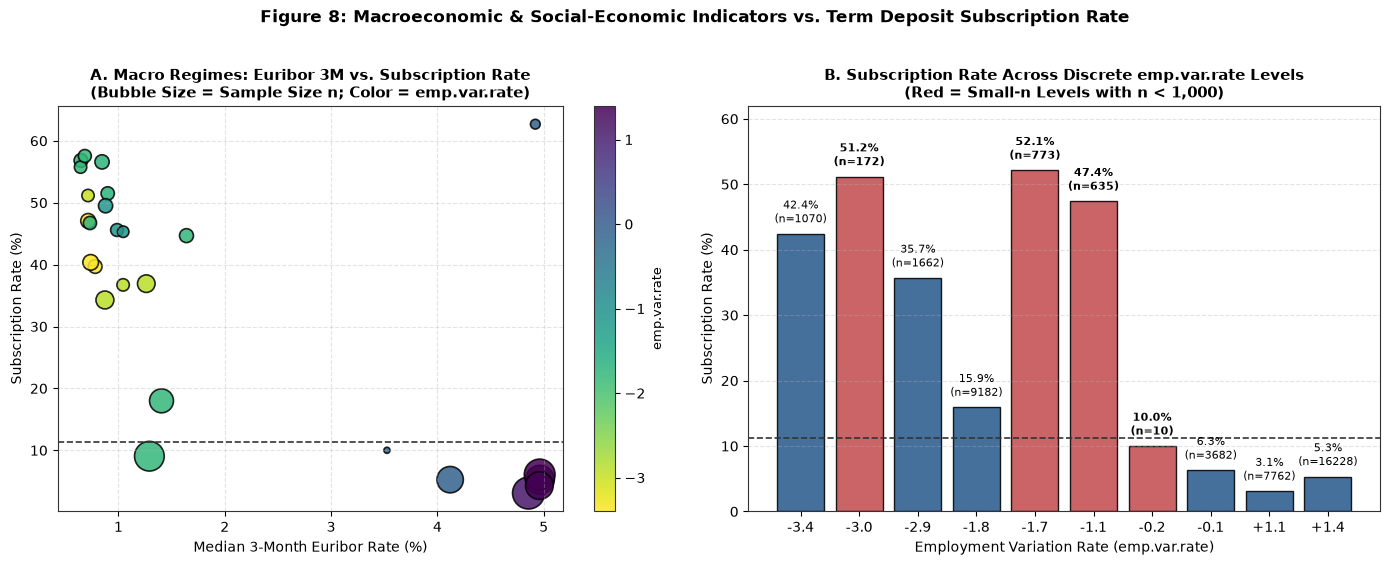

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

reg = df.groupby(['emp.var.rate', 'nr.employed', 'cons.price.idx']).agg(
    n=('y', 'count'), yes=('y', 'sum'), rate=('y', lambda s: s.mean()*100), euribor=('euribor3m', 'median')
).reset_index()

scatter = axes[0].scatter(reg['euribor'], reg['rate'], s=np.sqrt(reg['n'])*6, c=reg['emp.var.rate'],
                          cmap='viridis_r', alpha=0.85, edgecolors='black', linewidth=1.2)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('emp.var.rate', fontsize=9.5)
axes[0].axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[0].set_title('A. Macro Regimes: Euribor 3M vs. Subscription Rate\n(Bubble Size = Sample Size n; Color = emp.var.rate)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Median 3-Month Euribor Rate (%)', fontsize=10)
axes[0].set_ylabel('Subscription Rate (%)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.35)

emp_st = df.groupby('emp.var.rate')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reset_index()
emp_st['label'] = [f"{r['emp.var.rate']:+.1f}" for _, r in emp_st.iterrows()]
bar_c = [COLOR_WARN if n < 1000 else COLOR_MAIN for n in emp_st['n']]
bars2 = axes[1].bar(emp_st['label'], emp_st['rate'], color=bar_c, edgecolor='black', alpha=0.88)
axes[1].axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[1].set_ylim(0, 62)
axes[1].set_title('B. Subscription Rate Across Discrete emp.var.rate Levels\n(Red = Small-n Levels with n < 1,000)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Employment Variation Rate (emp.var.rate)', fontsize=10)
axes[1].set_ylabel('Subscription Rate (%)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.35)
for bar, (_, r) in zip(bars2, emp_st.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['rate'] + 1.2,
                 f"{r['rate']:.1f}%\n(n={int(r['n'])})", ha='center', va='bottom', fontsize=7.8,
                 fontweight=('bold' if r['n']<1000 else 'normal'))

plt.suptitle('Figure 8: Macroeconomic & Social-Economic Indicators vs. Term Deposit Subscription Rate', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig8_macro_regimes_analysis.png', dpi=200, bbox_inches='tight')
plt.show()


## 8. Categorical `"unknown"` Audit & Target Rates (`fig9_unknown_categories_audit.png`)


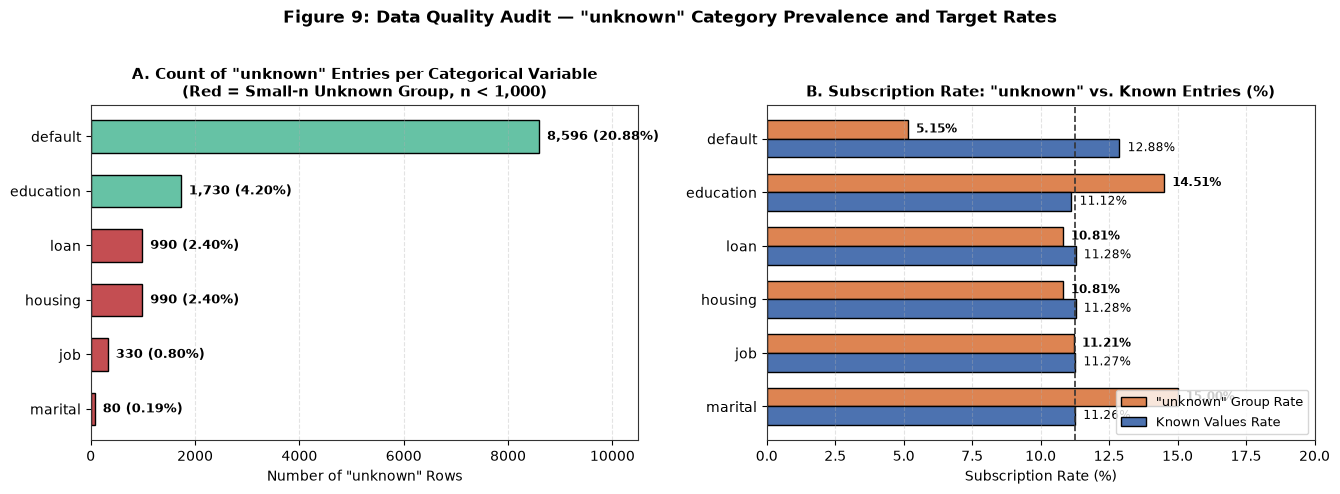

In [12]:
unk_rows = []
for col in ['default', 'education', 'housing', 'loan', 'job', 'marital']:
    sub_u = df[df[col] == 'unknown']
    sub_k = df[df[col] != 'unknown']
    unk_rows.append({
        'variable': col, 'unk_n': len(sub_u), 'unk_pct': len(sub_u) / len(df) * 100,
        'unk_yes': int(sub_u['y'].sum()), 'unk_rate': sub_u['y'].mean() * 100, 'known_rate': sub_k['y'].mean() * 100
    })
unk_df = pd.DataFrame(unk_rows).sort_values(by='unk_n', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
b1 = axes[0].barh(unk_df['variable'], unk_df['unk_n'],
                  color=[COLOR_WARN if n < 1000 else '#66C2A5' for n in unk_df['unk_n']],
                  edgecolor='black', height=0.6)
axes[0].set_xlim(0, 10500)
axes[0].set_title('A. Count of "unknown" Entries per Categorical Variable\n(Red = Small-n Unknown Group, n < 1,000)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Number of "unknown" Rows', fontsize=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.35)
for bar, (_, r) in zip(b1, unk_df.iterrows()):
    axes[0].text(r['unk_n'] + 150, bar.get_y() + bar.get_height()/2,
                 f"{int(r['unk_n']):,} ({r['unk_pct']:.2f}%)", va='center', fontsize=9, fontweight='bold')

y_pos = np.arange(len(unk_df))
h = 0.35
axes[1].barh(y_pos + h/2, unk_df['unk_rate'], height=h, color=COLOR_YES, edgecolor='black', label='"unknown" Group Rate')
axes[1].barh(y_pos - h/2, unk_df['known_rate'], height=h, color=COLOR_NO, edgecolor='black', label='Known Values Rate')
axes[1].axvline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(unk_df['variable'])
axes[1].set_xlim(0, 20)
axes[1].set_title('B. Subscription Rate: "unknown" vs. Known Entries (%)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Subscription Rate (%)', fontsize=10)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
for idx, (_, r) in enumerate(unk_df.iterrows()):
    axes[1].text(r['unk_rate'] + 0.3, idx + h/2, f"{r['unk_rate']:.2f}%", va='center', fontsize=8.5, fontweight='bold')
    axes[1].text(r['known_rate'] + 0.3, idx - h/2, f"{r['known_rate']:.2f}%", va='center', fontsize=8.5)

plt.suptitle('Figure 9: Data Quality Audit — "unknown" Category Prevalence and Target Rates', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig9_unknown_categories_audit.png', dpi=200, bbox_inches='tight')
plt.show()
